In [1]:
import itertools
from ast import literal_eval
import os

import numpy as np
import pandas as pd
from scipy.integrate import trapezoid

import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from matplotlib.ticker import MaxNLocator
import seaborn as sns

from mg_sampling import PROJECT_DIR
from mg_sampling.constants import RT
from mg_sampling.tools import read_plumed, read_plumed_fes, range_to_edges, edges_to_range, finitemin, finitemax, block_analysis, read_wsv
from mg_sampling.bias import bias_fn

LABELS = {
    'amber_tip3p': "Amber/TIP3P",
    'mMg_tip3p': "microMg/TIP3P",
    'nMg_tip3p': "nanoMg/TIP3P", 
    'mMg_opc': "microMg/OPC",
    'ecc_spce': "AmberECC/SPCE",
}

FORCEFIELDS_ARCHIVE = ['amber_tip3p', 'mMg_tip3p', 'nMg_tip3p', 'mMg_opc', 'ecc_spce']
FORCEFIELDS = ['mMg_tip3p']

os.makedirs('figures/metad', exist_ok=True)
os.makedirs('figures/metad/archive', exist_ok=True)

### Free energy surface (Hills)

In [2]:
def plot_metad_hills(path, ax):
    cv_names, (x_range, y_range), fes = read_plumed_fes(f'{path}/fes.dat')

    x_edges, y_edges = range_to_edges(x_range), range_to_edges(y_range)
    extent = [*x_edges[[0, -1]], *y_edges[[0, -1]]]

    im = ax.imshow(fes.T, extent=extent, origin='lower', aspect=1, cmap='terrain')
    # cf = ax.contour(fes.T, colors=['black'], linewidths=[1, 0.2], extent=extent)
    cbar = plt.colorbar(im)
    cbar.set_label("FES [$k_\mathrm{B}T$]")

    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    ax.yaxis.set_major_locator(MaxNLocator(integer=True))
    ax.grid(False)
    #ax.plot([0, 1, 2, 1, 0], [6, 7, 6, 5, 6], color='white', linestyle='dashed', linewidth=1)

    ax.set_xlabel("$n_\mathrm{O_P}$")
    ax.set_ylabel("$n_\mathrm{O_W}$")


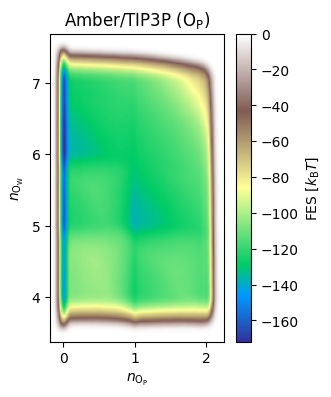

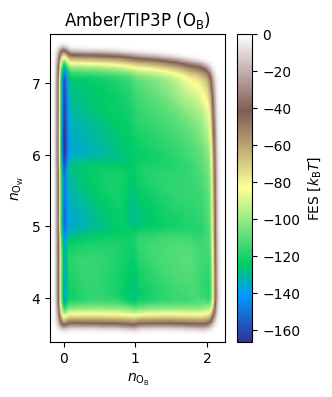

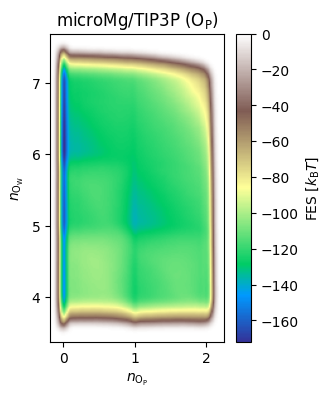

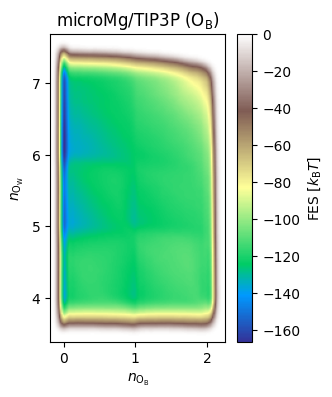

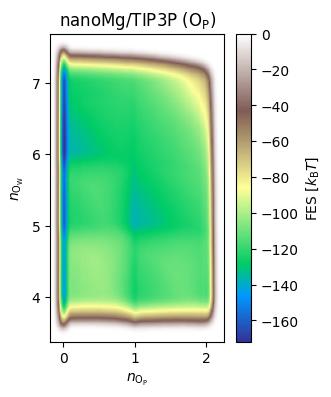

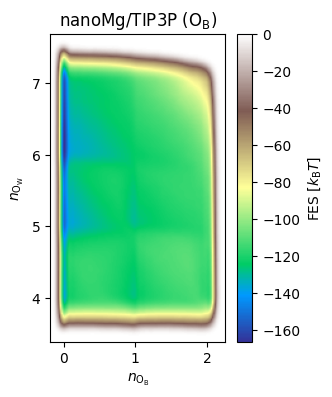

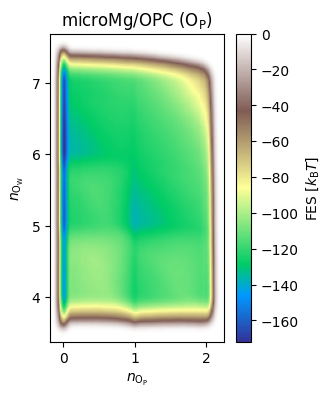

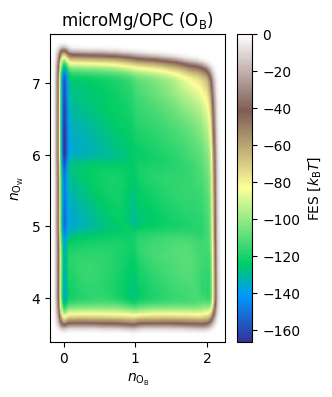

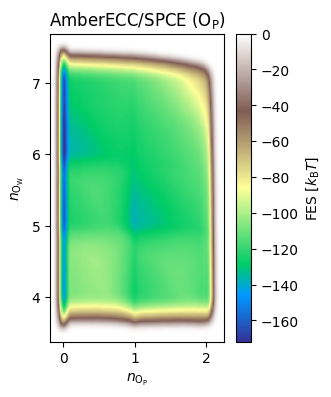

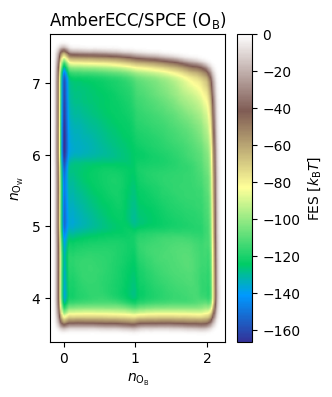

In [3]:
for ff in FORCEFIELDS_ARCHIVE:
    fig, ax = plt.subplots(figsize=(3,4))
    plot_metad_hills(PROJECT_DIR / f'metad/archive/op_mMg_tip3p', ax)
    ax.set_title(LABELS[ff] + " ($\mathrm{O_P}$)")
    plt.savefig(f'figures/metad/archive/metad_hills_op_{ff}.pdf')

    fig, ax = plt.subplots(figsize=(3,4))
    plot_metad_hills(PROJECT_DIR / f'metad/archive/ob_mMg_tip3p', ax)
    ax.set_xlabel("$n_\mathrm{O_B}$")
    ax.set_title(LABELS[ff] + " ($\mathrm{O_B}$)")
    plt.savefig(f'figures/metad/archive/metad_hills_ob_{ff}.pdf')

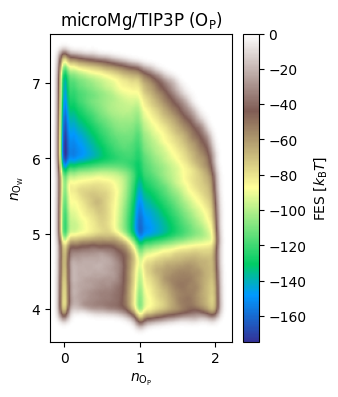

In [4]:
for ff in FORCEFIELDS:
    fig, ax = plt.subplots(figsize=(3,4))
    plot_metad_hills(PROJECT_DIR / f'metad/op_mMg_tip3p', ax)
    ax.set_title(LABELS[ff] + " ($\mathrm{O_P}$)")
    plt.savefig(f'figures/metad/metad_hills_op_{ff}.pdf')

    #fig, ax = plt.subplots(figsize=(3,4))
    #plot_metad_hills(PROJECT_DIR / f'metad/archive/ob_mMg_tip3p', ax)
    #ax.set_xlabel("$n_\mathrm{O_B}$")
    #ax.set_title(LABELS[ff] + " ($\mathrm{O_B}$)")
    #plt.savefig(f'figures/metad/archive/metad_hills_ob_{ff}.pdf')

### Free energy surface (Reweighted)

In [5]:
def plot_metad_fes(path, ax, nox='nop'):
    colvar = read_plumed(f'{path}/COLVAR')
    bins = np.linspace(0, 2, 41), np.linspace(4, 7, 61)

    bias = colvar['metad.bias']  # kJ/mol
    weights = np.exp(bias/RT)

    # Remove nop == 0
    x, y = colvar[nox], colvar['now']
    weights[x <= 0] = 0

    ρ_avg, x_edges, y_edges = np.histogram2d(x, y, bins=bins, density=True, weights=weights)
    with np.errstate(divide='ignore'):
        fes = -np.log(ρ_avg)
    fes -= finitemin(fes)

    extent = [*x_edges[[0, -1]], *y_edges[[0, -1]]]
    levels = np.arange(0, finitemax(fes), 2)

    im = ax.imshow(fes.T, extent=extent, origin='lower', aspect=1, cmap='RdPu_r')
    cf = ax.contour(fes.T, colors=['black'], linewidths=[1, 0.2], extent=extent, levels=levels)
    cbar = plt.colorbar(im)
    cbar.add_lines(cf)
    cbar.set_label("FES [$k_\mathrm{B}T$]")

    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    ax.yaxis.set_major_locator(MaxNLocator(integer=True))
    ax.grid(False)
    # ax.plot([0, 1, 2, 1, 0], [6, 7, 6, 5, 6], color='white', linestyle='dashed', linewidth=1)

    ax.set_xlabel("$n_\mathrm{O_P}$" if nox == 'nop' else 'nob')
    ax.set_ylabel("$n_\mathrm{O_W}$")

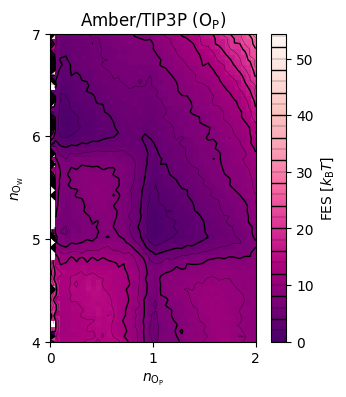

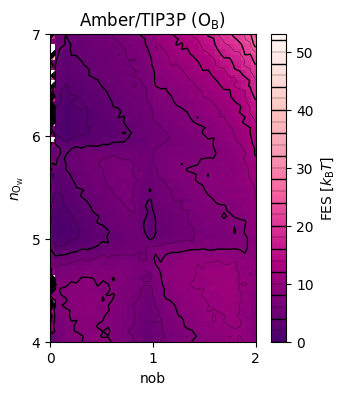

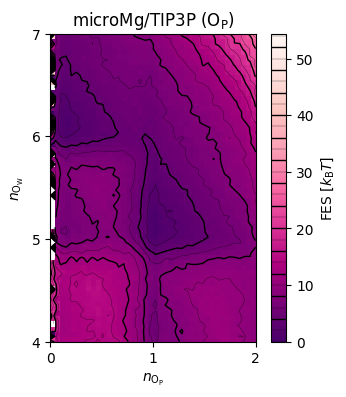

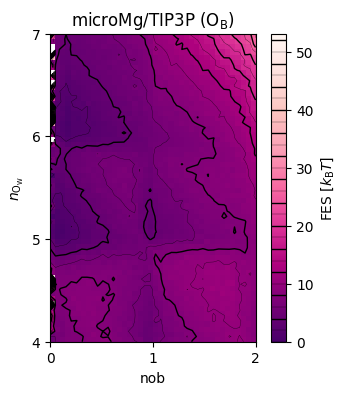

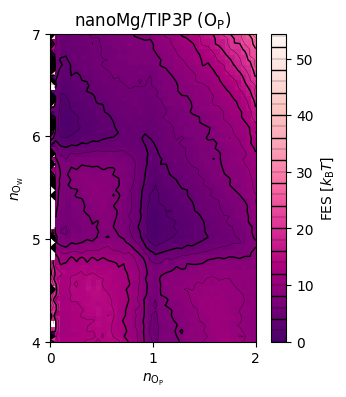

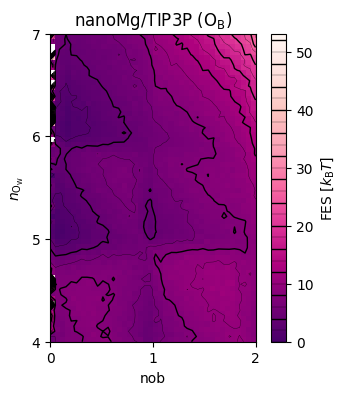

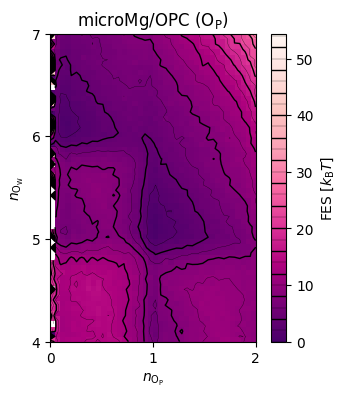

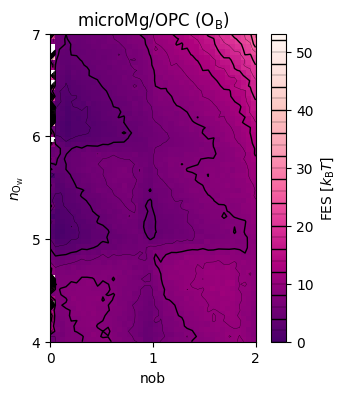

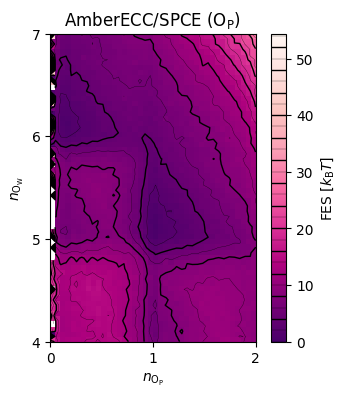

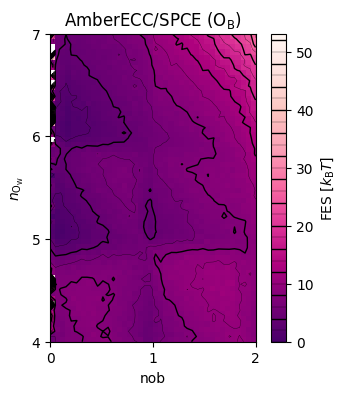

In [6]:
for ff in FORCEFIELDS_ARCHIVE:
    fig, ax = plt.subplots(figsize=(4,4))
    plot_metad_fes(PROJECT_DIR / f'metad/archive/op_mMg_tip3p', ax)
    ax.set_title(LABELS[ff] + " ($\mathrm{O_P}$)")
    plt.savefig(f'figures/metad/archive/metad_fes_op_{ff}.pdf')

    fig, ax = plt.subplots(figsize=(4,4))
    plot_metad_fes(PROJECT_DIR / f'metad/archive/ob_mMg_tip3p', ax, nox='nob')
    ax.set_title(LABELS[ff] + " ($\mathrm{O_B}$)")
    plt.savefig(f'figures/metad/archive/metad_fes_ob_{ff}.pdf')

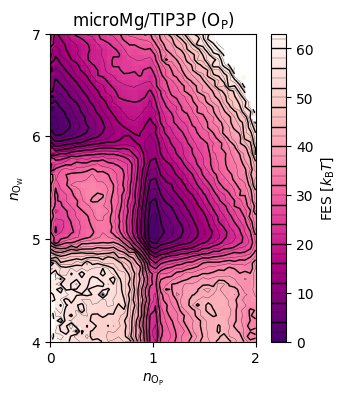

In [7]:
for ff in FORCEFIELDS:
    fig, ax = plt.subplots(figsize=(4,4))
    plot_metad_fes(PROJECT_DIR / f'metad/op_mMg_tip3p', ax)
    ax.set_title(LABELS[ff] + " ($\mathrm{O_P}$)")
    plt.savefig(f'figures/metad/metad_fes_op_{ff}.pdf')

In [8]:
def plot_metad_fes_err(path, ax, nox='nop'):
    colvar = read_plumed(f'{path}/COLVAR')
    x_edges, y_edges = np.linspace(0, 2, 41), np.linspace(4, 7, 61)
    bins = (x_edges, y_edges)

    bias = colvar['metad.bias']  # kJ/mol
    weights = np.exp(bias/RT)

    # Remove nop == 0
    x, y = colvar[nox], colvar['now']
    weights[x <= 0] = 0

    def get_fes(x, y, w):
        ρ_avg, _, _ = np.histogram2d(x, y, bins=bins, density=True, weights=w)
        with np.errstate(divide='ignore'):
            fes = -np.log(ρ_avg)
        fes -= finitemin(fes)
        return fes
    _, fes_stderr = block_analysis(x, y, weights, func=get_fes, n_blocks=6)

    extent = [*x_edges[[0, -1]], *y_edges[[0, -1]]]
    levels = np.arange(0, finitemax(fes_stderr), 2)

    im = ax.imshow(fes_stderr.T, extent=extent, origin='lower', aspect=1, cmap='OrRd', vmin=0)
    cf = ax.contour(fes_stderr.T, colors=['black'], linewidths=[1, 0.2], extent=extent, levels=levels)
    cbar = plt.colorbar(im)
    cbar.add_lines(cf)
    cbar.set_label("Std. Err. FES [$k_\mathrm{B}T$]")

    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    ax.yaxis.set_major_locator(MaxNLocator(integer=True))
    ax.grid(False)
    # ax.plot([0, 1, 2, 1, 0], [6, 7, 6, 5, 6], color='white', linestyle='dashed', linewidth=1)

    ax.set_xlabel("$n_\mathrm{O_P}$" if nox == 'nop' else 'nob')
    ax.set_ylabel("$n_\mathrm{O_W}$")

/leonardo_work/EUHPC_R02_136/Olivier/mg_sampling/.venv/lib/python3.11/site-packages/numpy/_core/_methods.py:185: RuntimeWarning: invalid value encountered in subtract
  x = asanyarray(arr - arrmean)
/leonardo_work/EUHPC_R02_136/Olivier/mg_sampling/.venv/lib/python3.11/site-packages/numpy/_core/_methods.py:185: RuntimeWarning: invalid value encountered in subtract
  x = asanyarray(arr - arrmean)
/leonardo_work/EUHPC_R02_136/Olivier/mg_sampling/.venv/lib/python3.11/site-packages/numpy/_core/_methods.py:185: RuntimeWarning: invalid value encountered in subtract
  x = asanyarray(arr - arrmean)
/leonardo_work/EUHPC_R02_136/Olivier/mg_sampling/.venv/lib/python3.11/site-packages/numpy/_core/_methods.py:185: RuntimeWarning: invalid value encountered in subtract
  x = asanyarray(arr - arrmean)
/leonardo_work/EUHPC_R02_136/Olivier/mg_sampling/.venv/lib/python3.11/site-packages/numpy/_core/_methods.py:185: RuntimeWarning: invalid value encountered in subtract
  x = asanyarray(arr - arrmean)
/leon

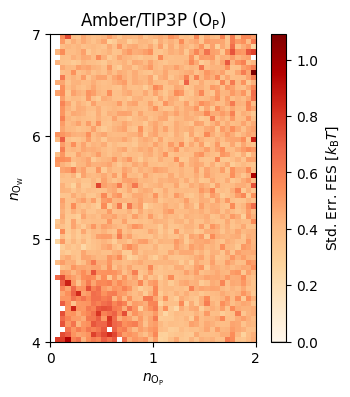

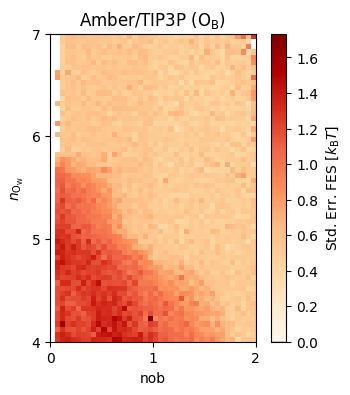

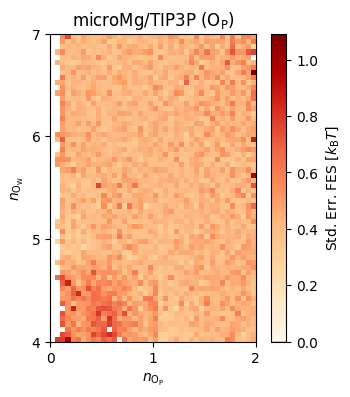

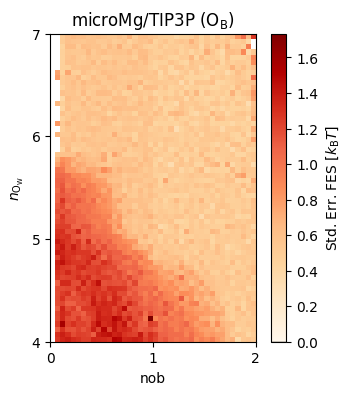

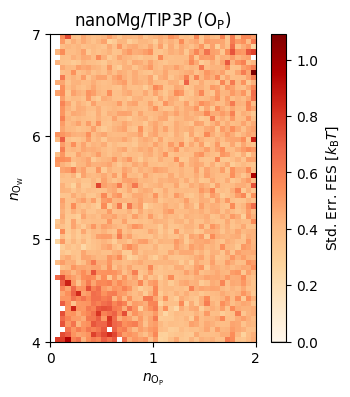

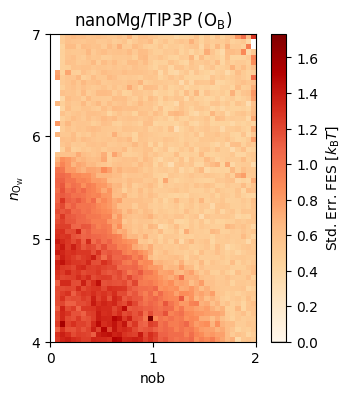

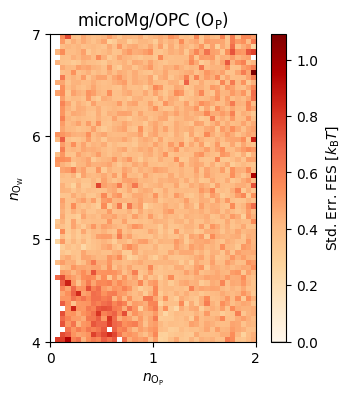

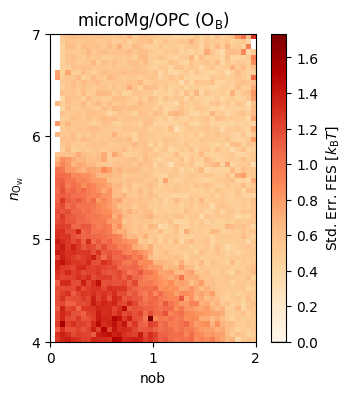

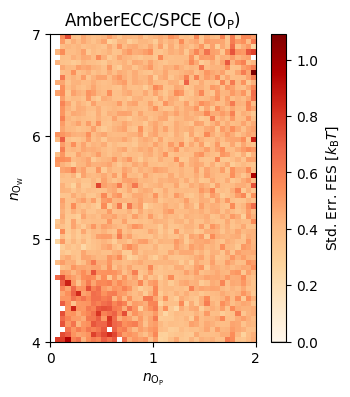

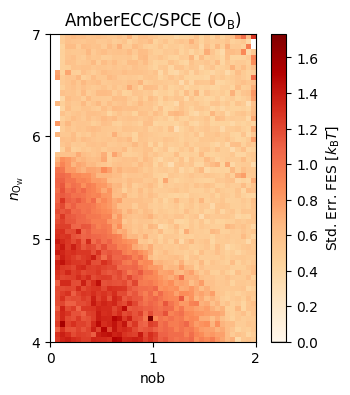

In [9]:
for ff in FORCEFIELDS_ARCHIVE:
    fig, ax = plt.subplots(figsize=(4,4))
    plot_metad_fes_err(PROJECT_DIR / f'metad/archive/op_mMg_tip3p', ax)
    ax.set_title(LABELS[ff] + " ($\mathrm{O_P}$)")
    plt.savefig(f'figures/metad/archive/metad_fes_err_op_{ff}.pdf')

    fig, ax = plt.subplots(figsize=(4,4))
    plot_metad_fes_err(PROJECT_DIR / f'metad/archive/ob_mMg_tip3p', ax, nox='nob')
    ax.set_title(LABELS[ff] + " ($\mathrm{O_B}$)")
    plt.savefig(f'figures/metad/archive/metad_fes_err_ob_{ff}.pdf')

/leonardo_work/EUHPC_R02_136/Olivier/mg_sampling/.venv/lib/python3.11/site-packages/numpy/_core/_methods.py:185: RuntimeWarning: invalid value encountered in subtract
  x = asanyarray(arr - arrmean)


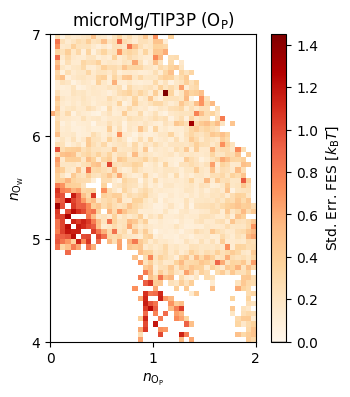

In [10]:
for ff in FORCEFIELDS:
    fig, ax = plt.subplots(figsize=(4,4))
    plot_metad_fes_err(PROJECT_DIR / f'metad/op_mMg_tip3p', ax)
    ax.set_title(LABELS[ff] + " ($\mathrm{O_P}$)")
    plt.savefig(f'figures/metad/metad_fes_err_op_{ff}.pdf')

### Timeseries

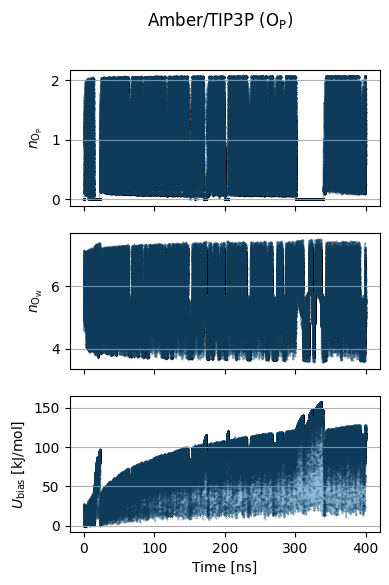

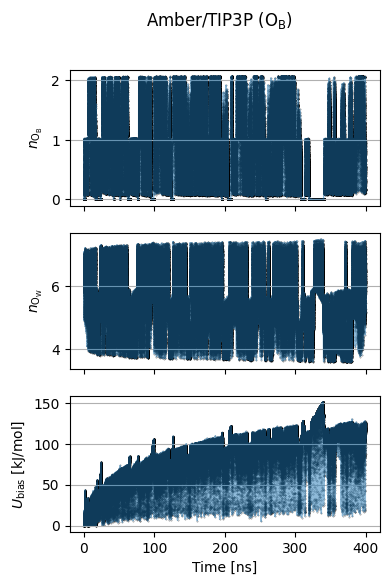

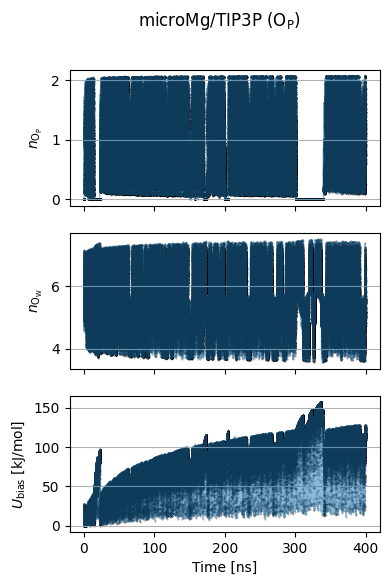

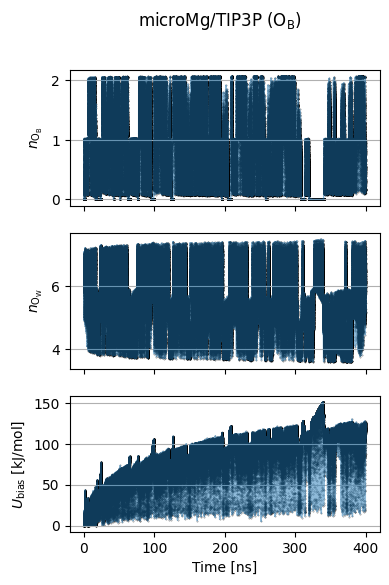

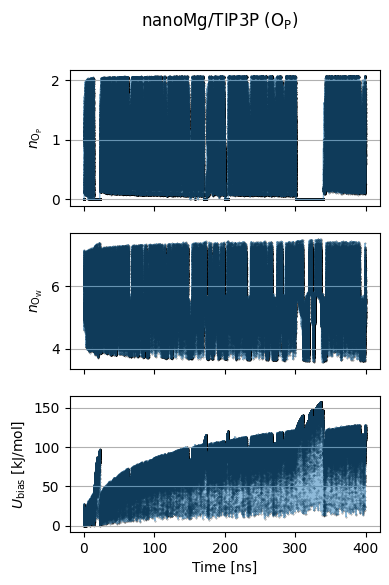

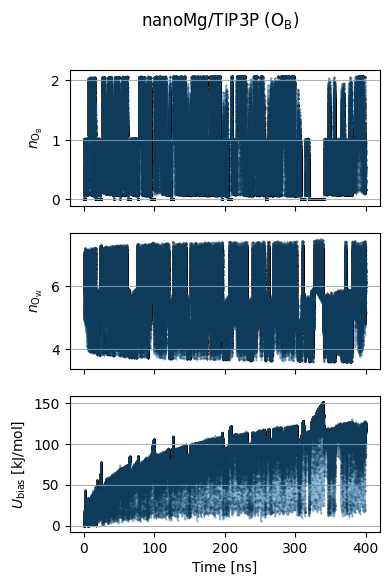

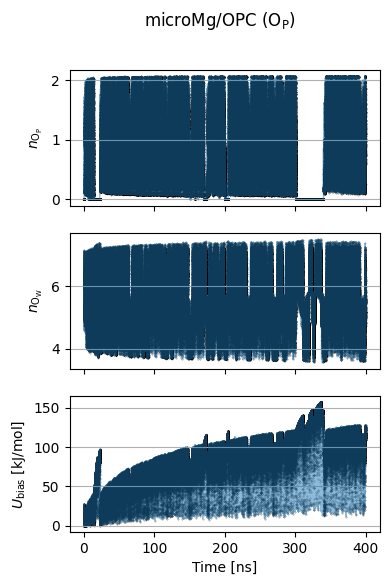

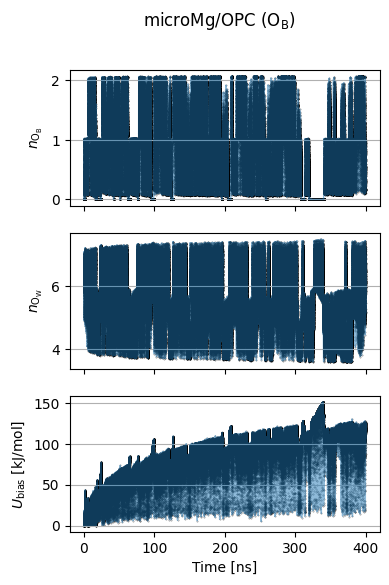

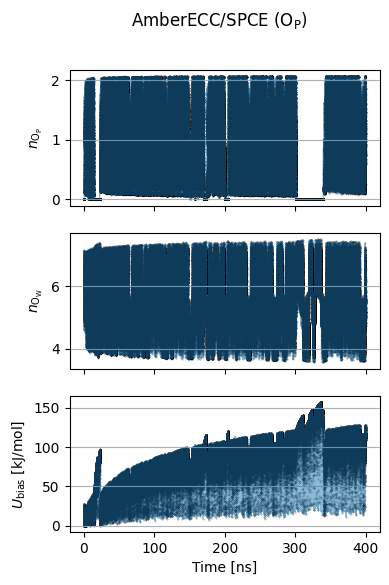

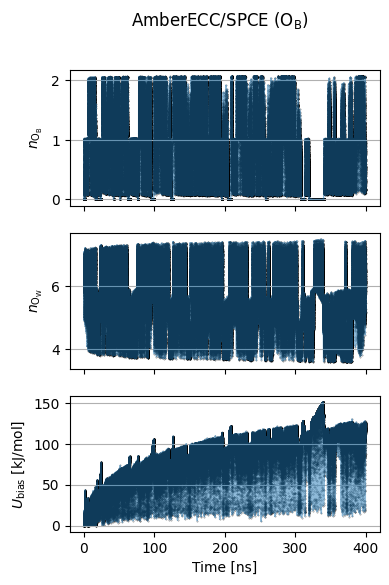

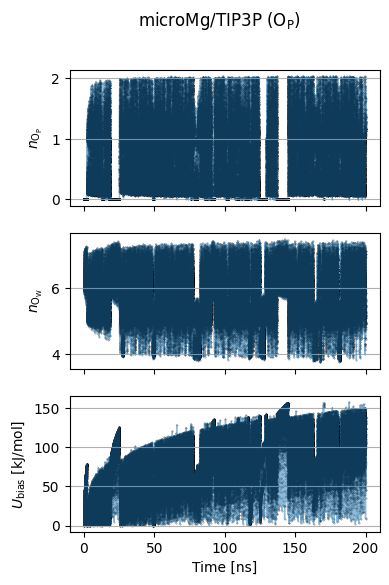

In [11]:
def plot_metad_timeseries(path, axarr, columns, labels):
    colvar = read_plumed(f'{path}/COLVAR')
    t_range = colvar['time'] / 1000

    for ax, col, label in zip(axarr, columns, labels):
        ax.plot(t_range, colvar[col], lw=1, alpha=0.5, rasterized=True)
        ax.scatter(t_range, colvar[col], s=0.1, alpha=0.5, c='k', rasterized=True)
        ax.set_ylabel(label)
        ax.grid(axis='y')

    axarr[-1].set_xlabel(r'Time [ns]')
    return axarr

for ff in FORCEFIELDS_ARCHIVE:
    fig, axarr = plt.subplots(nrows=3, figsize=(4, 6), sharex=True)
    plot_metad_timeseries(PROJECT_DIR / f'metad/archive/op_mMg_tip3p', axarr, ['nop', 'now', 'metad.bias'], ["$n_\mathrm{O_P}$", "$n_\mathrm{O_W}$", "$U_\mathrm{bias}$ [kJ/mol]"])
    fig.suptitle(LABELS[ff] + " ($\mathrm{O_P}$)")
    plt.savefig(f'figures/metad/archive/metad_timeseries_op_{ff}.pdf')

    fig, axarr = plt.subplots(nrows=3, figsize=(4, 6), sharex=True)
    plot_metad_timeseries(PROJECT_DIR / f'metad/archive/ob_mMg_tip3p', axarr, ['nob', 'now', 'metad.bias'], ["$n_\mathrm{O_B}$", "$n_\mathrm{O_W}$", "$U_\mathrm{bias}$ [kJ/mol]"])
    fig.suptitle(LABELS[ff] + " ($\mathrm{O_B}$)")
    plt.savefig(f'figures/metad/archive/metad_timeseries_ob_{ff}.pdf')

for ff in FORCEFIELDS:
    fig, axarr = plt.subplots(nrows=3, figsize=(4, 6), sharex=True)
    plot_metad_timeseries(PROJECT_DIR / f'metad/op_mMg_tip3p', axarr, ['nop', 'now', 'metad.bias'], ["$n_\mathrm{O_P}$", "$n_\mathrm{O_W}$", "$U_\mathrm{bias}$ [kJ/mol]"])
    fig.suptitle(LABELS[ff] + " ($\mathrm{O_P}$)")
    plt.savefig(f'figures/metad/metad_timeseries_op_{ff}.pdf')